# Cálculo de reposição de estoque — StockFlow (Gold análise → Gold reposição)

Sprint 6. Segue a **seção 6 da Pesquisa de Métodos de Previsão** (estoque de segurança, ponto de pedido e quantidade sugerida) e usa o modelo escolhido a partir da comparação da Sprint 4 (`experiments/sprint4_previsao/`).

- Entrada (Gold — análise): `data/gold/vendas_analise.parquet`.
- Saídas (Gold — reposição):
  - `data/gold/reposicao.parquet`: uma linha por loja × produto, com previsão, erro do modelo, estoque de segurança, ponto de pedido, quantidade sugerida e alerta, nos parâmetros padrão;
  - `data/gold/reposicao_previsao_diaria.parquet`: previsão diária dos próximos 30 dias por loja × produto, para o dashboard recalcular a sugestão quando a Renata muda os parâmetros.
- Registro: `docs/log_tratamento.md`, seção Gold → reposição.

**Decisões da sprint**

| Tema | Decisão | Motivo |
|---|---|---|
| Modelo | Regressão linear com calendário (tendência, dia da semana e mês em senos e cossenos), a mesma da Sprint 4 | Menor WAPE nos três horizontes (25,3% em 7 dias, 12,9% em 14, 12,5% em 30), empatada com a Ridge, e com coeficientes que dá para explicar |
| Prazo de entrega (L) | 1 dia por padrão, ajustável no dashboard | A base não tem prazo do fornecedor. Na base, o pedido entra no estoque no dia seguinte (seção 2), então o prazo implícito é 1 dia |
| Período de revisão (R) | 7 dias por padrão (a Renata revisa o pedido uma vez por semana), ajustável | Política de revisão periódica |
| Nível de serviço | 95% (z = 1,65) para todos os itens, ajustável | Pesquisa de métodos, seção 6; EDA, seção 10.1 |
| "Hoje" | 30/01/2024, último dia da base. Estoque atual = `estoque` desse dia (estoque do início do dia) | A base é histórica |
| Alerta de ruptura | Regra: estoque atual abaixo do ponto de pedido. Sem classificador | O bônus de modelagem já é atendido pela regressão; a regra sai direto do cálculo |

## 1. Importações, leitura da Gold e estilo dos gráficos

In [1]:
import os
import subprocess
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats

GOLD = "data/gold/vendas_analise.parquet"

# Funciona no Colab e localmente: se a Gold não estiver acessível, clona o repositório
if not os.path.exists(GOLD):
    if os.path.exists(os.path.join("..", GOLD)):
        os.chdir("..")
    else:
        subprocess.run(["git", "clone", "https://github.com/juliamariateixeiraa/StockFlow.git"], check=True)
        os.chdir("StockFlow")

df = pd.read_parquet(GOLD)
item = ["loja_id", "produto_id"]
df = df.sort_values(item + ["data"]).reset_index(drop=True)
print(df.shape)
print("Período:", df["data"].min().date(), "a", df["data"].max().date())
print("Itens (loja × produto):", df.groupby(item).ngroups)

(76000, 37)
Período: 2022-01-01 a 2024-01-30
Itens (loja × produto): 100


In [2]:
# Mesma paleta e estilo do notebook de EDA
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
AZUL, LARANJA, VERDE, VERMELHO, CINZA = CORES[0], CORES[1], CORES[2], CORES[7], "#898781"

mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=CORES), "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 100, "figure.figsize": (10, 4),
})

## 2. Parâmetros

Valores padrão da reposição. No dashboard, os três primeiros viram controles e a sugestão é recalculada a partir da previsão diária salva na Gold.

**Por que o prazo padrão é 1 dia:** a pesquisa de métodos sugeria 7 dias, mas a base mostra outra coisa. Na maior parte dos dias, o estoque de amanhã é exatamente o de hoje, menos a venda, mais o pedido: o pedido chega no dia seguinte. Por isso o estoque da base cobre só cerca de 3 dias de demanda (`cobertura_estoque`, mediana 2,8). Com 7 dias de prazo, quase todo item ficaria em alerta crítico, e o painel perderia o sentido.

In [3]:
PRAZO_ENTREGA = 1      # L, dias entre fazer o pedido e a mercadoria chegar
PERIODO_REVISAO = 7    # R, dias até a próxima revisão do pedido
NIVEL_SERVICO = 0.95   # chance de não faltar produto no ciclo
Z = stats.norm.ppf(NIVEL_SERVICO)

HOJE = df["data"].max()        # 30/01/2024: o "hoje" da simulação
DIAS_TESTE = 182               # últimos ~6 meses antes de hoje, para medir o erro do modelo
DIAS_CALIBRACAO = 98           # primeira parte do teste: calcula o σ usado no teste da regra
HORIZONTE_SALVO = 30           # dias de previsão diária salvos para o dashboard

print(f"z = {Z:.3f}  |  hoje = {HOJE.date()}  |  L + R = {PRAZO_ENTREGA + PERIODO_REVISAO} dias")

z = 1.645  |  hoje = 2024-01-30  |  L + R = 8 dias


In [4]:
# Evidência do prazo de 1 dia: o estoque segue o fluxo estoque − venda + pedido
amanha = df.groupby(item)["estoque"].shift(-1)
fluxo = df["estoque"] - df["unidades_vendidas"] + df["unidades_pedidas"]
print(f"Dias em que estoque de amanhã = estoque − venda + pedido de hoje: {(amanha == fluxo)[amanha.notna()].mean():.0%}")
print(f"Cobertura de estoque mediana: {df['cobertura_estoque'].median():.1f} dias")

Dias em que estoque de amanhã = estoque − venda + pedido de hoje: 69%
Cobertura de estoque mediana: 2.8 dias


## 3. Modelo: regressão linear com calendário

A mesma regressão da Sprint 4 (`matriz_calendario` em `experiments/sprint4_previsao/motor.py`), ajustada por mínimos quadrados para cada loja × produto, com a `demanda` como alvo:

- intercepto e tendência (anos desde o início do treino);
- dia da semana em seno e cosseno (ciclo de 7 dias);
- mês em seno e cosseno (ciclo de 12 meses).

A regressão usa só o calendário, que é conhecido no futuro. Promoção e epidemia ficam fora porque não se sabe o valor delas nos próximos dias (Sprint 4, README). A previsão negativa vira zero.

In [5]:
def matriz_calendario(datas, origem):
    d = pd.DatetimeIndex(datas)
    t = (d - origem).days.to_numpy(dtype=float)
    w = d.day_of_week.to_numpy(dtype=float)
    m = d.month.to_numpy(dtype=float)
    return np.column_stack([
        np.ones(len(d)), t / 365.25,
        np.sin(2 * np.pi * w / 7), np.cos(2 * np.pi * w / 7),
        np.sin(2 * np.pi * (m - 1) / 12), np.cos(2 * np.pi * (m - 1) / 12),
    ])

def ajustar(y):
    """Coeficientes da regressão para a série diária y (índice = data)."""
    beta = np.linalg.lstsq(matriz_calendario(y.index, y.index[0]), y.to_numpy(dtype=float), rcond=None)[0]
    return beta, y.index[0]

def prever(beta, origem, datas):
    return np.maximum(matriz_calendario(datas, origem) @ beta, 0)

series = {chave: g.set_index("data")["demanda"].astype(float) for chave, g in df.groupby(item)}
dias = pd.Series({k: s.index.to_series().diff().dropna().dt.days.max() for k, s in series.items()})
print("Maior intervalo entre dias seguidos de um item:", dias.max())

Maior intervalo entre dias seguidos de um item: 1


## 4. Erro do modelo no teste (σ)

A seção 6 da pesquisa de métodos pede o σ do **erro do modelo no teste**, e não a variação total da demanda. Assim o estoque de segurança cai quando a previsão melhora.

Para cada item, o modelo é treinado com os dados até 01/08/2023 e prevê os 182 dias seguintes, até 30/01/2024. O erro é `real − previsto` em cada dia: positivo quando a demanda veio acima do previsto, que é o caso em que falta produto.

In [6]:
inicio_teste = HOJE - pd.Timedelta(DIAS_TESTE - 1, unit="D")
epidemia = df.set_index(item + ["data"])["epidemia"]

erros, modelos_teste = [], {}
for (loja, produto), y in series.items():
    treino, teste = y[y.index < inicio_teste], y[y.index >= inicio_teste]
    beta, origem = ajustar(treino)
    modelos_teste[(loja, produto)] = (beta, origem)
    erros.append(pd.DataFrame({
        "loja_id": loja, "produto_id": produto, "data": teste.index,
        "real": teste.to_numpy(), "previsto": prever(beta, origem, teste.index),
    }))
erros = pd.concat(erros, ignore_index=True)
erros["erro"] = erros["real"] - erros["previsto"]
erros["epidemia"] = epidemia.loc[list(zip(erros["loja_id"], erros["produto_id"], erros["data"]))].to_numpy()

print("Teste:", inicio_teste.date(), "a", HOJE.date(), "|", len(erros), "dias × item")
print(f"WAPE diário no teste: {100 * erros['erro'].abs().sum() / erros['real'].sum():.1f}%")
print(f"Erro médio: {erros['erro'].mean():.1f} (fora da epidemia: {erros.loc[erros.epidemia == 0, 'erro'].mean():.1f}; "
      f"na epidemia: {erros.loc[erros.epidemia == 1, 'erro'].mean():.1f})")
print(f"Dias de epidemia no teste: {erros['epidemia'].mean():.0%}")

Teste: 2023-08-02 a 2024-01-30 | 18200 dias × item
WAPE diário no teste: 33.0%
Erro médio: -6.2 (fora da epidemia: 1.0; na epidemia: -40.9)
Dias de epidemia no teste: 17%


**Interpretação:** o WAPE diário é maior que o da Sprint 4 porque lá o erro era medido no **total da janela**, e os erros de dias diferentes se compensam em parte. Fora da epidemia, o erro médio fica perto de zero, ou seja, o modelo não erra sistematicamente para cima nem para baixo. Na epidemia, a demanda cai e o modelo, que não conhece a epidemia, prevê demais. Esse erro gera estoque sobrando, e não falta de produto.

### 4.1 Os erros são aproximadamente normais?

A fórmula do estoque de segurança assume erros aproximadamente normais (pesquisa de métodos, seção 6). Para conferir, cada erro é dividido pelo desvio do seu item, e o resultado é comparado com a normal.

Assimetria: 0.40
Erros abaixo de +z·σ: 95.4% (a normal promete 95%)


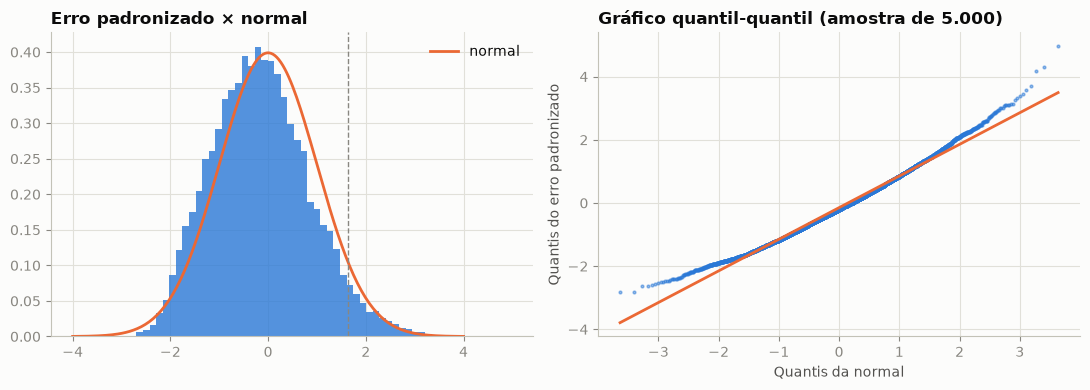

In [7]:
erros["erro_padronizado"] = erros["erro"] / erros.groupby(item)["erro"].transform("std")
dentro = (erros["erro_padronizado"] <= Z).mean()
print(f"Assimetria: {stats.skew(erros['erro']):.2f}")
print(f"Erros abaixo de +z·σ: {dentro:.1%} (a normal promete {NIVEL_SERVICO:.0%})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(erros["erro_padronizado"], bins=60, density=True, color=AZUL, alpha=0.8)
x = np.linspace(-4, 4, 200)
ax1.plot(x, stats.norm.pdf(x), color=LARANJA, label="normal")
ax1.axvline(Z, color=CINZA, ls="--", lw=1)
ax1.set_title("Erro padronizado × normal")
ax1.legend(frameon=False)
stats.probplot(erros["erro_padronizado"].sample(5000, random_state=0), dist="norm", plot=ax2)
ax2.get_lines()[0].set(color=AZUL, markersize=2, alpha=0.5)
ax2.get_lines()[1].set(color=LARANJA)
ax2.set(title="Gráfico quantil-quantil (amostra de 5.000)", xlabel="Quantis da normal", ylabel="Quantis do erro padronizado")
plt.tight_layout()
plt.show()

**Interpretação:** a assimetria é pequena e positiva (0,4). A cauda direita, de demanda acima do previsto, é a que causa ruptura, e ela é um pouco mais pesada que a normal acima de 2σ. No nível de 95%, a aproximação acerta: 95,4% dos erros ficam abaixo de +1,65σ. Para 98% ou 99%, a normal subestimaria o risco, como a EDA já indicava (seção 10.1). Por isso o painel avisa que níveis acima de 95% são aproximados.

### 4.2 Os erros de dias seguidos são independentes?

A fórmula z × σ × √n assume que o erro de um dia não tem relação com o do dia seguinte. Se um dia acima do previsto costuma ser seguido de outro dia acima, os erros se somam, e o erro no total de n dias é **maior** que σ × √n.

In [8]:
auto = erros.groupby(item)["erro"].apply(lambda s: s.autocorr(1)).rename("autocorrelacao")
print(f"Autocorrelação de 1 dia entre os erros: mediana {auto.median():.2f} "
      f"(10% dos itens abaixo de {auto.quantile(0.1):.2f}, 90% abaixo de {auto.quantile(0.9):.2f})")
print(f"Itens com autocorrelação positiva: {(auto > 0).mean():.0%}")

Autocorrelação de 1 dia entre os erros: mediana 0.20 (10% dos itens abaixo de 0.02, 90% abaixo de 0.40)
Itens com autocorrelação positiva: 92%


**Interpretação:** quase todos os itens têm autocorrelação positiva, perto de 0,2. A causa principal são os blocos de epidemia, que deixam o erro negativo por várias semanas seguidas. Por isso o σ × √n da pesquisa de métodos **subestima** o erro no período de reposição.

**Ajuste:** o erro diário é tratado como um processo AR(1), em que cada dia guarda uma parte ρ do erro do dia anterior. A variância da soma de n dias passa a ser

$$\sigma_n^2 = \sigma^2 \left[n + 2\sum_{k=1}^{n-1}(n-k)\,\rho^k\right]$$

Com ρ = 0, a conta volta a ser σ × √n. Valores negativos de ρ são tratados como 0, para o ajuste nunca reduzir o estoque de segurança.

In [9]:
def desvio_periodo(sigma, rho, n):
    """Desvio do erro somado em n dias, com erros diários AR(1)."""
    rho = np.clip(rho, 0, 0.95)
    k = np.arange(1, n)
    soma = n + 2 * np.sum((n - k)[None, :] * np.power.outer(np.atleast_1d(rho), k), axis=1)
    return np.atleast_1d(sigma) * np.sqrt(soma)

n = PRAZO_ENTREGA + PERIODO_REVISAO
fator = desvio_periodo(1.0, auto.median(), n)[0] / np.sqrt(n)
print(f"Para o item mediano, o ajuste aumenta o desvio de {n} dias em {fator - 1:.0%}")

Para o item mediano, o ajuste aumenta o desvio de 8 dias em 20%


## 5. Teste inicial da regra: o estoque de segurança cumpre os 95%?

Antes de usar a regra, ela é testada com dados que não entraram no cálculo do σ:

1. σ e ρ de cada item vêm só dos primeiros 98 dias do teste (calibração);
2. os 84 dias restantes viram 10 janelas de L + R = 8 dias;
3. em cada janela, a regra acerta se a demanda real coube na previsão + estoque de segurança.

Se a regra estiver certa, deve acertar em cerca de 95% das 1.000 janelas (100 itens × 10).

In [10]:
resultado, calibracao = [], {}
for (loja, produto), e in erros.groupby(item):
    e = e.reset_index(drop=True)
    cal = e["erro"].iloc[:DIAS_CALIBRACAO]
    sigma, rho = cal.std(), cal.autocorr(1)
    calibracao[(loja, produto)] = (sigma, max(rho, 0))
    for ajuste, d in [("Sem ajuste (σ·√n)", sigma * np.sqrt(n)), ("Com ajuste AR(1)", desvio_periodo(sigma, rho, n)[0])]:
        for k in range((len(e) - DIAS_CALIBRACAO) // n):
            janela = e.iloc[DIAS_CALIBRACAO + k * n: DIAS_CALIBRACAO + (k + 1) * n]
            resultado.append({"ajuste": ajuste, "coube": janela["erro"].sum() <= Z * d, "estoque_seguranca": Z * d})
resultado = pd.DataFrame(resultado)
teste_regra = resultado.groupby("ajuste", sort=False).agg(
    janelas=("coube", "size"), nivel_servico_observado=("coube", "mean"), estoque_seguranca_medio=("estoque_seguranca", "mean"))
teste_regra.style.format({"nivel_servico_observado": "{:.1%}", "estoque_seguranca_medio": "{:.0f}"})

,janelas,nivel_servico_observado,estoque_seguranca_medio
ajuste,,,
Sem ajuste (σ·√n),1000,92.9%,197
Com ajuste AR(1),1000,95.9%,241


**Interpretação:** sem o ajuste, a regra fica abaixo dos 95% prometidos, porque ignora que os erros se somam. Com o ajuste AR(1), o nível observado chega aos 95% com um estoque de segurança cerca de 20% maior. O ajuste fica: ele cumpre o que o painel promete para a Renata.

## 6. Erro do modelo por item

Para a recomendação de hoje, σ e ρ são recalculados com os 182 dias do teste: mais dados dão uma estimativa mais estável.

In [11]:
erro_item = erros.groupby(item).agg(sigma_erro=("erro", "std")).join(auto.rename("rho_erro"))
erro_item["rho_erro"] = erro_item["rho_erro"].clip(lower=0)
erro_item.describe().round(2)

,sigma_erro,rho_erro
count,100.00,100.00
mean,41.73,0.20
std,6.26,0.13
min,29.04,0.00
25%,37.74,0.12
50%,42.99,0.20
75%,47.06,0.28
max,52.89,0.49


## 7. Previsão a partir de hoje

O modelo é treinado de novo com todo o histórico até 29/01/2024 e prevê a demanda dos 30 dias a partir de 30/01/2024. O estoque atual é o `estoque` de 30/01/2024, que é o estoque do início do dia (Silver, etapa 7b).

In [12]:
datas_futuras = pd.date_range(HOJE, periods=HORIZONTE_SALVO, freq="D")
ultimo_dia = df[df["data"] == HOJE].set_index(item)

previsao, coeficientes = [], []
for (loja, produto), y in series.items():
    beta, origem = ajustar(y[y.index < HOJE])
    previsao.append(pd.DataFrame({"loja_id": loja, "produto_id": produto, "data": datas_futuras,
                                  "dia": np.arange(1, HORIZONTE_SALVO + 1),
                                  "demanda_prevista": prever(beta, origem, datas_futuras)}))
    coeficientes.append({"loja_id": loja, "produto_id": produto, "nivel": beta[0], "tendencia_ano": beta[1],
                         "amplitude_semana": np.hypot(beta[2], beta[3]), "amplitude_ano": np.hypot(beta[4], beta[5])})
previsao = pd.concat(previsao, ignore_index=True)
coeficientes = pd.DataFrame(coeficientes).set_index(item)
print(previsao.shape)
coeficientes.describe().round(1)

(3000, 5)


,nivel,tendencia_ano,amplitude_semana,amplitude_ano
count,100.0,100.0,100.0,100.0
mean,107.7,-3.2,2.4,9.1
std,17.6,3.3,1.2,3.0
min,74.6,-10.6,0.5,3.5
25%,96.0,-5.6,1.4,7.0
50%,112.9,-3.5,2.2,8.8
75%,122.3,-1.0,3.2,11.0
max,132.0,4.0,6.9,16.4


**O que pesa na previsão (explicabilidade):** o **nível** de cada item (mediana de cerca de 110 unidades por dia) explica quase toda a previsão. A **sazonalidade anual** é o segundo componente, com amplitude mediana de 9 unidades por dia. A **tendência** (−3,5 unidades por dia a cada ano) e o **dia da semana** (amplitude de 2) pesam pouco, como a EDA mostrou (seção 5: demanda de 103 a 105 em todos os dias). Na prática, a sugestão de compra é o ritmo normal do item, corrigido pela época do ano, mais uma margem para o erro do modelo.

## 8. Estoque de segurança, ponto de pedido e quantidade sugerida

Para cada loja × produto, com D(n) = demanda prevista somada nos próximos n dias:

| Conta | Fórmula |
|---|---|
| Estoque de segurança | ES = z × σ(L + R), com σ(L + R) da seção 4.2 |
| Ponto de pedido | PP = D(L) + z × σ(L) |
| Quantidade sugerida | Q = máx(0, D(L + R) + ES − estoque atual), arredondada para cima |
| Alerta | **Crítico:** estoque atual < D(L), vai faltar antes de a entrega chegar, mesmo pedindo hoje. **Pedir agora:** estoque atual < PP. **OK:** acima do ponto de pedido |

O ponto de pedido usa o desvio de L dias, e a quantidade usa o de L + R dias, porque o pedido de hoje precisa durar até a entrega do próximo. É a política de revisão periódica. A pesquisa de métodos escreveu a fórmula só com L; com revisão semanal, o período de risco é L + R.

In [13]:
def calcular_reposicao(previsao, erro_item, estoque_atual, prazo, revisao, nivel_servico):
    """Recomendação por loja × produto. Usada aqui e no dashboard."""
    z = stats.norm.ppf(nivel_servico)
    prevista = previsao.pivot_table(index=["loja_id", "produto_id"], columns="dia", values="demanda_prevista")
    base = erro_item.join(estoque_atual).copy()
    base["demanda_prevista_L"] = prevista.loc[base.index, range(1, prazo + 1)].sum(axis=1)
    base["demanda_prevista_LR"] = prevista.loc[base.index, range(1, prazo + revisao + 1)].sum(axis=1)
    sigma_l = desvio_periodo(base["sigma_erro"].to_numpy(), base["rho_erro"].to_numpy(), prazo)
    sigma_lr = desvio_periodo(base["sigma_erro"].to_numpy(), base["rho_erro"].to_numpy(), prazo + revisao)
    base["estoque_seguranca"] = z * sigma_lr
    base["ponto_pedido"] = base["demanda_prevista_L"] + z * sigma_l
    base["quantidade_sugerida"] = np.ceil(np.maximum(
        base["demanda_prevista_LR"] + base["estoque_seguranca"] - base["estoque_atual"], 0)).astype("int64")
    base["alerta"] = np.select(
        [base["estoque_atual"] < base["demanda_prevista_L"], base["estoque_atual"] < base["ponto_pedido"]],
        ["Crítico", "Pedir agora"], "OK")
    base["valor_compra"] = base["quantidade_sugerida"] * base["preco_atual"]
    return base

estoque_atual = ultimo_dia[["categoria", "regiao", "estoque", "preco"]].rename(
    columns={"estoque": "estoque_atual", "preco": "preco_atual"})
reposicao = calcular_reposicao(previsao, erro_item, estoque_atual, PRAZO_ENTREGA, PERIODO_REVISAO, NIVEL_SERVICO)
reposicao[["estoque_atual", "demanda_prevista_L", "demanda_prevista_LR", "estoque_seguranca",
           "ponto_pedido", "quantidade_sugerida", "valor_compra"]].describe().round(0)

,estoque_atual,demanda_prevista_L,demanda_prevista_LR,estoque_seguranca,ponto_pedido,quantidade_sugerida,valor_compra
count,100.0,100.0,100.0,100.0,100.0,100.0,100.0
mean,290.0,99.0,781.0,233.0,168.0,724.0,47290.0
std,206.0,18.0,147.0,39.0,26.0,255.0,29497.0
min,61.0,64.0,488.0,157.0,113.0,73.0,4534.0
25%,136.0,87.0,684.0,201.0,152.0,554.0,23618.0
50%,216.0,104.0,828.0,228.0,179.0,776.0,43334.0
75%,391.0,112.0,894.0,263.0,187.0,938.0,68480.0
max,1039.0,135.0,1092.0,313.0,214.0,1188.0,127952.0


## 9. Resultado da reposição em 30/01/2024

In [14]:
resumo = reposicao.groupby("alerta").agg(itens=("quantidade_sugerida", "size"),
                                         unidades=("quantidade_sugerida", "sum"),
                                         valor=("valor_compra", "sum")).reindex(["Crítico", "Pedir agora", "OK"]).fillna(0)
print(f"Itens com compra sugerida: {(reposicao.quantidade_sugerida > 0).sum()} de {len(reposicao)}")
print(f"Total sugerido: {reposicao.quantidade_sugerida.sum():,.0f} unidades | R$ {reposicao.valor_compra.sum():,.2f}")
resumo

Itens com compra sugerida: 100 de 100
Total sugerido: 72,411 unidades | R$ 4,729,040.13


,itens,unidades,valor
alerta,,,
Crítico,11,11096,674447.70
Pedir agora,26,23707,1558875.69
OK,63,37608,2495716.74


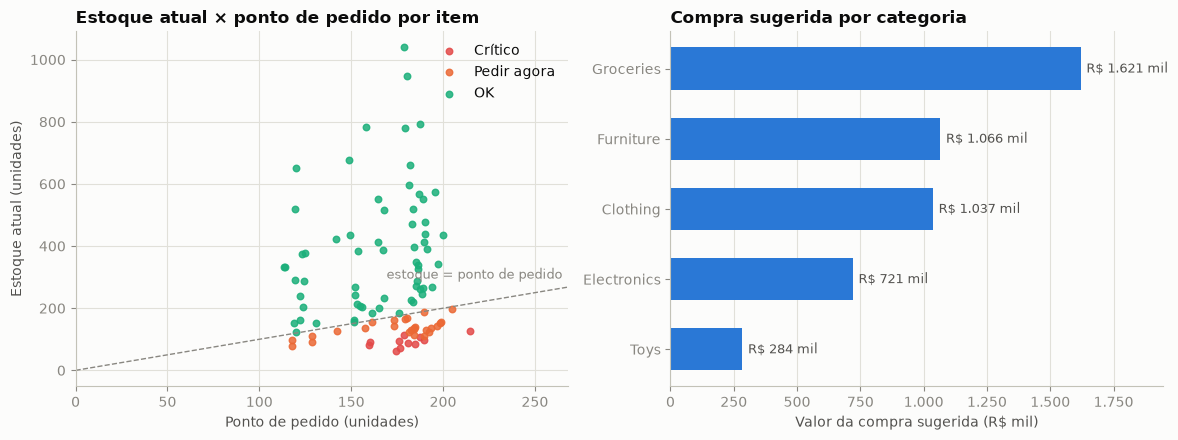

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
cores_alerta = {"Crítico": VERMELHO, "Pedir agora": LARANJA, "OK": VERDE}
for alerta in ["Crítico", "Pedir agora", "OK"]:
    g = reposicao[reposicao["alerta"] == alerta]
    ax1.scatter(g["ponto_pedido"], g["estoque_atual"], s=22, color=cores_alerta[alerta], label=alerta, alpha=0.85)
lim = [0, reposicao["ponto_pedido"].max() * 1.25]
ax1.plot(lim, lim, color=CINZA, lw=1, ls="--")
ax1.annotate("estoque = ponto de pedido", (lim[1], lim[1]), xytext=(-4, 6), textcoords="offset points",
             ha="right", color=CINZA, fontsize=9)
ax1.set_xlim(lim)
ax1.set(xlabel="Ponto de pedido (unidades)", ylabel="Estoque atual (unidades)", title="Estoque atual × ponto de pedido por item")
ax1.legend(frameon=False)

por_categoria = reposicao.groupby("categoria")["valor_compra"].sum().sort_values()
ax2.barh(por_categoria.index, por_categoria.to_numpy(), color=AZUL, height=0.6)
for y_, v in enumerate(por_categoria.to_numpy()):
    ax2.annotate(f"R$ {v / 1000:,.0f} mil".replace(",", "."), (v, y_), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax2.set(xlabel="Valor da compra sugerida (R$ mil)", title="Compra sugerida por categoria")
ax2.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}".replace(",", ".")))
ax2.set_xlim(right=por_categoria.max() * 1.2)
ax2.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [16]:
# Os itens mais urgentes, como aparecem para a Renata
colunas = ["categoria", "estoque_atual", "demanda_prevista_L", "ponto_pedido", "quantidade_sugerida", "valor_compra", "alerta"]
reposicao.assign(folga=reposicao.estoque_atual - reposicao.ponto_pedido).sort_values("folga")[colunas].head(10).round(0)

categoria  estoque_atual  demanda_prevista_L  \
loja_id produto_id                                                   
S002    P0018          Clothing             61               110.0   
        P0011         Groceries             73               101.0   
        P0008         Groceries             85               110.0   
        P0016          Clothing             88               119.0   
        P0006          Clothing             98               122.0   
S001    P0009          Clothing            128               135.0   
S003    P0003       Electronics             95               104.0   
        P0019         Groceries            108               114.0   
S001    P0015              Toys             80                87.0   
S003    P0010         Groceries            111               110.0   

                    ponto_pedido  quantidade_sugerida  valor_compra  \
loja_id produto_id                                                    
S002    P0018              175.0                 1030       32105.0   
        P0011              177.0                  962       80616.0   
        P0008              185.0                 1046       28221.0   
        P0016              181.0                 1027       93970.0   
        P0006              190.0                 1071       68094.0   
S001    P0009              214.0                 1188      107336.0   
S003    P0003              176.0                  949       87270.0   
        P0019              188.0                 1024       62925.0   
S001    P0015              160.0                  882       12242.0   
S003    P0010              190.0                  989       45296.0   

                         alerta  
loja_id produto_id               
S002    P0018           Crítico  
        P0011           Crítico  
        P0008           Crítico  
        P0016           Crítico  
        P0006           Crítico  
S001    P0009           Crítico  
S003    P0003           Crítico  
        P0019           Crítico  
S001    P0015           Crítico  
S003    P0010       Pedir agora

**Interpretação:** os pontos abaixo da linha tracejada têm menos estoque do que o necessário para atravessar o prazo de entrega com 95% de segurança, e são os que o painel manda pedir agora. Os vermelhos não têm estoque nem para a demanda prevista de hoje, então devem faltar antes de o pedido chegar amanhã. Os itens acima da linha também recebem compra sugerida, porque com revisão semanal o pedido de hoje precisa durar até a próxima entrega, daqui a 8 dias. Mas para eles não há urgência.

### 9.1 Sensibilidade aos parâmetros

Como a quantidade total sugerida muda quando a Renata ajusta o nível de serviço e o prazo de entrega.

In [17]:
sens = []
for nivel in [0.90, 0.95, 0.98, 0.99]:
    for prazo in [1, 3, 7]:
        r = calcular_reposicao(previsao, erro_item, estoque_atual, prazo, PERIODO_REVISAO, nivel)
        sens.append({"nível de serviço": f"{nivel:.0%}", "prazo (dias)": prazo,
                     "estoque de segurança total": r["estoque_seguranca"].sum(),
                     "compra sugerida (un.)": r["quantidade_sugerida"].sum(),
                     "itens em alerta": (r["alerta"] != "OK").sum()})
pd.DataFrame(sens).pivot(index="nível de serviço", columns="prazo (dias)",
                         values=["estoque de segurança total", "itens em alerta"]).round(0)

estoque de segurança total                   itens em alerta  \
prazo (dias)                              1        3        7               1   
nível de serviço                                                                
90%                                 18174.0  20450.0  24372.0            31.0   
95%                                 23326.0  26247.0  31281.0            37.0   
98%                                 29124.0  32772.0  39058.0            41.0   
99%                                 32990.0  37122.0  44242.0            43.0   

                               
prazo (dias)         3      7  
nível de serviço               
90%               73.0   97.0  
95%               76.0   98.0  
98%               79.0   99.0  
99%               82.0  100.0

**Interpretação:** passar de 95% para 99% de nível de serviço aumenta o estoque de segurança em cerca de 40% (z de 1,65 para 2,33). O prazo pesa ainda mais nos alertas: com 3 dias, a maioria dos itens já entra em alerta, porque o estoque da base cobre cerca de 3 dias. Por isso o prazo do fornecedor é o parâmetro que a Renata mais precisa informar certo.

## 10. Backtest: a regra teria evitado as faltas?

Como o estoque da base segue o fluxo (seção 2), dá para simular a regra no passado e comparar com a reposição que aconteceu de verdade na base.

- **Período:** os últimos 84 dias (07/11/2023 a 30/01/2024), os mesmos da seção 5. O modelo foi treinado antes de 02/08/2023 e o σ veio da calibração, então nada do período simulado entra na regra.
- **Início:** o estoque real da base em 07/11/2023.
- **A cada dia:** chega o que foi pedido L dias antes. Se é dia de revisão (a cada R dias) ou se a posição de estoque (estoque + pedidos a caminho) está abaixo do ponto de pedido, a regra pede o que falta para chegar a D(L + R) + ES. A demanda real do dia sai do estoque; se ela for maior ou igual ao estoque, é dia de ruptura (a mesma regra do rótulo da EDA).
- **Comparação:** os mesmos indicadores calculados com o estoque real da base.

In [18]:
inicio_bt = inicio_teste + pd.Timedelta(DIAS_CALIBRACAO, unit="D")
estoque_real = df.set_index(item + ["data"])["estoque"]

def simular(prazo, revisao, nivel_servico):
    z = stats.norm.ppf(nivel_servico)
    linhas = []
    for (loja, produto), y in series.items():
        beta, origem = modelos_teste[(loja, produto)]
        sigma, rho = calibracao[(loja, produto)]
        es = z * desvio_periodo(sigma, rho, prazo + revisao)[0]
        margem_pp = z * desvio_periodo(sigma, rho, prazo)[0]
        dias_bt = y.index[y.index >= inicio_bt]
        futuro = prever(beta, origem, pd.date_range(inicio_bt, periods=len(dias_bt) + prazo + revisao))
        estoque, a_caminho, pedidos = float(estoque_real[(loja, produto, inicio_bt)]), np.zeros(len(dias_bt) + prazo + 1), 0
        for i, dia in enumerate(dias_bt):
            estoque += a_caminho[i]
            posicao = estoque + a_caminho[i + 1:].sum()
            if i % revisao == 0 or posicao < futuro[i:i + prazo].sum() + margem_pp:
                q = np.ceil(max(futuro[i:i + prazo + revisao].sum() + es - posicao, 0))
                if q > 0:
                    a_caminho[i + prazo] += q
                    pedidos += 1
            demanda = y[dia]
            linhas.append({"ruptura": demanda >= estoque, "falta": max(demanda - estoque, 0),
                           "demanda": demanda, "estoque": estoque})
            estoque = max(estoque - demanda, 0)
        linhas[-1]["pedidos"] = pedidos
    r = pd.DataFrame(linhas)
    return {"dias com ruptura": r["ruptura"].mean(), "demanda atendida": 1 - r["falta"].sum() / r["demanda"].sum(),
            "estoque médio": r["estoque"].mean(), "pedidos por item": r["pedidos"].sum() / len(series)}

base_bt = df[df["data"] >= inicio_bt]
falta_base = (base_bt["demanda"] - base_bt["estoque"]).clip(lower=0)
comparacao = {"Base (reposição real)": {
    "dias com ruptura": (base_bt["demanda"] >= base_bt["estoque"]).mean(),
    "demanda atendida": 1 - falta_base.sum() / base_bt["demanda"].sum(),
    "estoque médio": base_bt["estoque"].mean(),
    "pedidos por item": (base_bt["unidades_pedidas"] > 0).sum() / len(series)}}
for revisao in [1, 3, 7]:
    nome = {1: "diária", 3: "a cada 3 dias", 7: "semanal"}[revisao]
    comparacao[f"StockFlow, revisão {nome}"] = simular(PRAZO_ENTREGA, revisao, NIVEL_SERVICO)
comparacao = pd.DataFrame(comparacao).T
comparacao.style.format({"dias com ruptura": "{:.1%}", "demanda atendida": "{:.1%}",
                         "estoque médio": "{:.0f}", "pedidos por item": "{:.0f}"})

,dias com ruptura,demanda atendida,estoque médio,pedidos por item
Base (reposição real),14.3%,93.9%,298,32
"StockFlow, revisão diária",3.4%,99.0%,226,83
"StockFlow, revisão a cada 3 dias",1.3%,99.5%,393,28
"StockFlow, revisão semanal",0.6%,99.7%,694,12


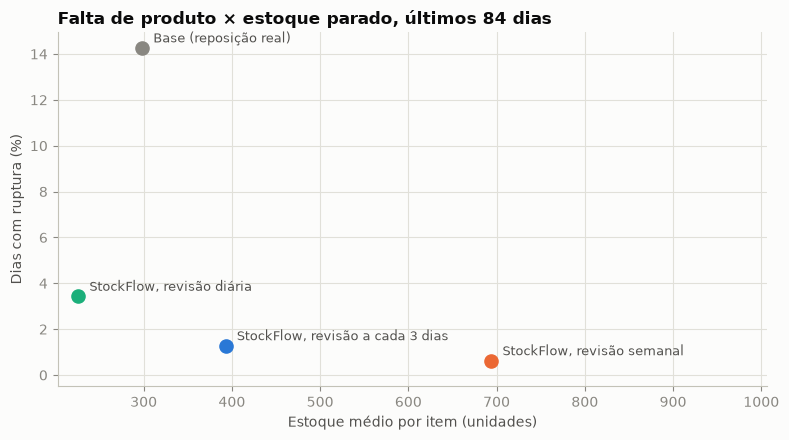

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
cores_bt = [CINZA, VERDE, AZUL, LARANJA]
for (nome, linha), cor in zip(comparacao.iterrows(), cores_bt):
    ax.scatter(linha["estoque médio"], 100 * linha["dias com ruptura"], s=90, color=cor, zorder=3)
    ax.annotate(nome, (linha["estoque médio"], 100 * linha["dias com ruptura"]), xytext=(8, 4),
                textcoords="offset points", fontsize=9, color="#52514e")
ax.set(xlabel="Estoque médio por item (unidades)", ylabel="Dias com ruptura (%)",
       title="Falta de produto × estoque parado, últimos 84 dias")
ax.set_ylim(bottom=-0.5)
ax.set_xlim(right=comparacao["estoque médio"].max() * 1.45)
plt.tight_layout()
plt.show()

**Interpretação:** nos 84 dias, a reposição real da base deixou faltar produto em 14,3% dos dias e atendeu 93,9% da demanda. Com a regra do StockFlow, a falta cai para 0,6% a 3,4% dos dias, dependendo do período de revisão. O período de revisão decide o que se troca por isso:

- **revisão diária (R = 1):** é a única que melhora tudo ao mesmo tempo, com menos falta e menos estoque que a base. Mas pede quase todo dia;
- **revisão a cada 3 dias:** 1,3% de falta, com menos pedidos que a base e cerca de 30% mais estoque;
- **revisão semanal (R = 7, o padrão):** quase não falta, com 12 pedidos em 84 dias, mas o estoque médio é mais que o dobro do da base.

O pedido semanal é o mais simples para a Renata, e o painel deixa ela trocar o período para ver o efeito. Esse resultado é o argumento central da solução: **com a mesma demanda, a regra reduz as faltas de 14% para menos de 4% dos dias**.

## 11. Salvar em `data/gold/`

In [20]:
os.makedirs("data/gold", exist_ok=True)
saida = reposicao.join(coeficientes[["tendencia_ano", "amplitude_semana", "amplitude_ano"]]).reset_index()
saida.insert(2, "data_referencia", HOJE)
saida["prazo_entrega"], saida["periodo_revisao"], saida["nivel_servico"] = PRAZO_ENTREGA, PERIODO_REVISAO, NIVEL_SERVICO
saida.to_parquet("data/gold/reposicao.parquet", index=False)
previsao.to_parquet("data/gold/reposicao_previsao_diaria.parquet", index=False)

for arquivo in ["data/gold/reposicao.parquet", "data/gold/reposicao_previsao_diaria.parquet"]:
    conferencia = pd.read_parquet(arquivo)
    print(arquivo, conferencia.shape, "| nulos:", int(conferencia.isna().sum().sum()))
saida.dtypes

data/gold/reposicao.parquet (100, 22) | nulos: 0
data/gold/reposicao_previsao_diaria.parquet (3000, 5) | nulos: 0


loja_id                        object
produto_id                     object
data_referencia        datetime64[us]
sigma_erro                    float64
rho_erro                      float64
categoria              string[python]
regiao                 string[python]
estoque_atual                   int64
preco_atual                   float64
demanda_prevista_L            float64
demanda_prevista_LR           float64
estoque_seguranca             float64
ponto_pedido                  float64
quantidade_sugerida             int64
alerta                         object
valor_compra                  float64
tendencia_ano                 float64
amplitude_semana              float64
amplitude_ano                 float64
prazo_entrega                   int64
periodo_revisao                 int64
nivel_servico                 float64
dtype: object

## 12. Principais conclusões

1. **A regra funciona.** No teste com dados que não entraram no cálculo, o estoque de segurança cumpriu o nível de serviço prometido de 95% (95,9%, seção 5). No backtest, ela reduz os dias com falta de 14,3% para 0,6% a 3,4% (seção 10).
2. **A fórmula da pesquisa precisava de um ajuste.** Os erros de dias seguidos se somam (autocorrelação de cerca de 0,2, puxada pela epidemia). Sem considerar isso, a regra entrega menos que os 95% prometidos. O ajuste AR(1) corrige isso sem mudar a ideia da fórmula.
3. **O prazo do fornecedor muda os alertas, e o período de revisão muda o estoque.** Com o prazo de 1 dia da base, 37 dos 100 itens pedem compra hoje (11 críticos). A revisão semanal quase elimina as faltas, mas mais que dobra o estoque médio. A revisão diária reduz as faltas e o estoque ao mesmo tempo (seções 9.1 e 10).
4. **A sugestão é explicável:** ela é o ritmo normal do item, corrigido pela época do ano, mais uma margem pelo erro do modelo (seção 7).

**Limitações:** o dado é sintético, e o prazo de 1 dia vem do comportamento da base, não de um fornecedor real. O backtest supõe que o fornecedor entrega tudo o que foi pedido no prazo, e não considera custo de pedido nem espaço de armazenagem. O modelo não sabe de promoções futuras: na semana de uma promoção, a Renata deve reforçar o pedido, já que a promoção aumenta a demanda em 30% (EDA, seção 14).